# 07 — Deep Learning Anomaly Detection

## 1. Objective

This notebook develops and examines deep-learning models for unsupervised anomaly detection in the Secure Water Treatment (SWaT) dataset.

The analysis builds on the data preparation, chronological partitioning, and LSTM Autoencoder work completed in the preceding notebooks. It focuses on two additional architectures: a Temporal Convolutional Network Autoencoder (TCN Autoencoder) and Unsupervised Anomaly Detection on Multivariate Time Series (USAD).

The objective is to investigate whether these architectures can learn patterns from normal industrial process observations and assign higher anomaly scores to observations that differ from those learned patterns.

## 2. Scope

This notebook covers:

- TCN Autoencoder methodology, implementation, training, and reconstruction-score analysis.
- USAD methodology, implementation, training, and anomaly-score analysis.
- Documentation of model configurations, training behaviour, computational requirements, and observed limitations.
- Preservation and verification of the resulting model artifacts and relevant outputs.

The LSTM Autoencoder developed in Notebook 05 remains part of the project's deep-learning model set. Its existing implementation and artifacts will be reused where appropriate rather than unnecessarily reproduced.

## 3. Methodological Principles

All implementations must follow the project's established data and evaluation protocol.

- Train the models using the designated normal training partition.
- Preserve chronological separation between training, threshold-calibration, and validation observations.
- Reuse the established 42-feature definition and training-fitted scaler where appropriate.
- Do not use attack labels to fit models, select model configurations, or determine anomaly thresholds.
- Record actual training outputs, score distributions, and computational costs without inventing results.
- Document observations and limitations before proceeding to the next stage.
- Keep final threshold selection and formal evaluation in Notebook 08.

## 4. Expected Outcome

The notebook will provide reproducible implementations and documented results for the TCN Autoencoder and USAD. Together with the existing LSTM Autoencoder, these models will form the project's deep-learning detector set for subsequent threshold calibration, comparative evaluation, and error analysis.

## 5. TCN Autoencoder — Methodological Foundations

### 5.1 Objective

The Temporal Convolutional Network Autoencoder (TCN Autoencoder) is an unsupervised deep-learning model that learns to reconstruct multivariate time-series windows from normal industrial process observations.

Unlike the LSTM Autoencoder, which uses recurrent layers to represent temporal dependencies, the TCN Autoencoder uses temporal convolutions. Dilated convolutions allow the network to incorporate information from a wider temporal context without requiring a recurrent operation at every timestep.

The model will be trained using the designated normal training partition. Its reconstruction errors will provide anomaly-oriented scores for subsequent analysis.

### 5.2 Input Representation

Each model input is a multivariate time-series window:

$$
X \in \mathbb{R}^{W \times F}
$$

where:

- $W = 30$ is the established sequence-window length.
- $F = 42$ is the number of selected sensor and actuator features.

A batch of windows is represented as:

$$
X \in \mathbb{R}^{B \times W \times F}
$$

where $B$ is the batch size.

The implementation must account for PyTorch's expected input layout for one-dimensional convolutions, which is typically:

$$
X \in \mathbb{R}^{B \times F \times W}
$$

Any necessary dimension permutation must be explicit and verified.

### 5.3 Temporal Convolutions and Dilation

A temporal convolution applies learnable filters across the time dimension. Dilation introduces gaps between filter positions, allowing a convolutional layer to access a wider temporal range without proportionally increasing the kernel size.

For a one-dimensional dilated causal convolution, the operation is:

$$
y_t = \sum_{i=0}^{K-1} w_i \, x_{t - d \cdot i}
$$

where:

- $x_t$ is the input sequence.
- $y_t$ is the output at timestep $t$.
- $w_i$ represents a learnable filter coefficient.
- $K$ is the kernel size.
- $d$ is the dilation factor.

The convolution is causal when the input is padded with $(K-1) \cdot d$ zeros on its left edge and the padded sequence is indexed from $1$; equivalently, $x_p = 0$ for all $p \leq 0$. Under that padding, the output $y_t$ depends only on $x_t$ and the preceding positions $x_{t-d}, x_{t-2d}, \ldots, x_{t-(K-1)d}$. No future observation $x_{t+j}$ with $j > 0$ contributes to $y_t$.

### 5.4 Receptive Field

The receptive field is the number of input timesteps that can influence an output position.

For a stack of $L$ dilated convolutional layers with common kernel size $K$ and dilations $d_1, d_2, \ldots, d_L$, the receptive field is:

$$
R = 1 + (K-1) \sum_{\ell=1}^{L} d_\ell
$$

$L$ in this formula is the total number of convolutional layers, not the number of TCN blocks. If a block contains two convolutions with the same dilation factor, its contribution to the sum is $2 \cdot d$ and to $L$ is $2$. This distinction matters when comparing against published configurations, which typically stack 2 convolutions per block.

For the reference configuration with four TCN blocks, dilation schedule $1, 2, 4, 8$, and kernel size $3$:

- If each block contains 1 convolution ($L = 4$, $d = [1, 2, 4, 8]$): $R = 1 + 2 \cdot (1+2+4+8) = 31$.
- If each block contains 2 convolutions ($L = 8$, $d = [1,1,2,2,4,4,8,8]$): $R = 1 + 2 \cdot 30 = 61$.
- If each block contains 3 convolutions ($L = 12$, $d = [1,1,1,2,2,2,4,4,4,8,8,8]$): $R = 1 + 2 \cdot 45 = 91$.

The reference reports a receptive field of 90 timesteps. That value is consistent with 3 convolutions per block (giving 91) but not with 1 or 2; it must be verified against the actual implementation, not inferred from the dilation schedule alone. The count reported here assumes no stride, no downsampling between blocks, and no extra conv layers on the residual path — any of those would change the effective receptive field.

Because this project's established input window contains 30 timesteps, the implementation must also be checked to confirm how its receptive field compares with the window length. If the computed receptive field exceeds 30, the network's output at early window positions will be computed from padded input only, and its reconstruction of those positions may be less informative than the middle and end of the window.

### 5.5 Encoder and Decoder

The encoder transforms the input sequence into a more compact representation of its temporal patterns. Dilated convolutional layers allow the encoder to represent dependencies across multiple temporal scales.

The decoder maps the encoded representation back to the original sequence dimensions.

For an input window $X$, the reconstructed output is denoted by:

$$
\hat{X} = f_{\theta}(X)
$$

where $f_{\theta}$ represents the trainable encoder–decoder network.

The reconstructed output must preserve the input window's temporal and feature dimensions:

$$
\hat{X} \in \mathbb{R}^{B \times W \times F}
$$

This shape requirement will be verified before training.

### 5.6 Reconstruction Loss

The model uses mean squared error (MSE) as its reconstruction objective:

$$
\mathcal{L}_{\mathrm{MSE}}
=
\frac{1}{B W F}
\sum_{b=1}^{B}
\sum_{t=1}^{W}
\sum_{f=1}^{F}
\left( X_{b,t,f} - \hat{X}_{b,t,f} \right)^2
$$

where:

- $X_{b,t,f}$ is the observed feature value.
- $\hat{X}_{b,t,f}$ is its reconstructed value.
- $B$, $W$, and $F$ denote batch size, window length, and feature count.

Minimizing this loss encourages the model to reconstruct the patterns represented in its training data.

### 5.7 Anomaly Scoring

After training, reconstruction error is calculated for each evaluated sequence.

For sequence $i$, the mean squared reconstruction error is:

$$
s_i =
\frac{1}{W F}
\sum_{t=1}^{W}
\sum_{f=1}^{F}
\left( X_{i,t,f} - \hat{X}_{i,t,f} \right)^2
$$

Higher scores indicate greater reconstruction error and are interpreted as greater anomalousness under this scoring convention.

High reconstruction error does not by itself establish a physical fault or cyberattack. Formal classifications will depend on the threshold-calibration and evaluation protocol defined in Notebook 08.

### 5.8 Training and Evaluation Controls

The implementation preserves the project's existing methodological controls:

- Use the established normal training partition for model fitting.
- Reuse the existing 42-feature definition and training-fitted scaler.
- Preserve chronological separation between training, threshold-calibration, and validation data.
- Avoid using attack labels for model fitting, architecture selection, or threshold selection.
- Verify model input and output dimensions before training.
- Record the actual configuration, training history, runtime, and reconstruction-score distributions.
- Save the fitted model and verify that it can be reloaded.
- Defer final threshold selection and formal evaluation to Notebook 08.

The TCN Autoencoder will be assessed using recorded evidence from this implementation. Results from the reference notebook will not be assumed to transfer to the current dataset or configuration.

In [1]:
# 6. TCN AUTOENCODER — REQUIRED ARTIFACT VERIFICATION

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

ARTIFACT_DIR = Path("/content/drive/MyDrive/swat-artifacts")
SCALER_PATH = ARTIFACT_DIR / "scaler.joblib"

if not ARTIFACT_DIR.is_dir():
    raise FileNotFoundError(
        f"Artifact directory not found: {ARTIFACT_DIR}"
    )

if not SCALER_PATH.is_file():
    raise FileNotFoundError(
        f"Training-fitted scaler not found: {SCALER_PATH}"
    )

print("Artifact verification: PASS")
print(f"Artifact directory: {ARTIFACT_DIR}")
print(f"Scaler file: {SCALER_PATH}")
print(f"Scaler size: {SCALER_PATH.stat().st_size / (1024 ** 2):.2f} MB")

Mounted at /content/drive
Artifact verification: PASS
Artifact directory: /content/drive/MyDrive/swat-artifacts
Scaler file: /content/drive/MyDrive/swat-artifacts/scaler.joblib
Scaler size: 0.00 MB


In [2]:
# 6.1 LOAD AND VERIFY THE EXISTING SCALER

import joblib
import numpy as np

# Load the scaler fitted on the designated training partition.
scaler = joblib.load(SCALER_PATH)

# Recover the established feature names and their ordering.
if not hasattr(scaler, "feature_names_in_"):
    raise AttributeError(
        "The saved scaler does not contain feature_names_in_. "
        "The established feature ordering must be verified separately."
    )

FEATURE_COLUMNS = list(scaler.feature_names_in_)

# Verify the expected feature count.
assert len(FEATURE_COLUMNS) == 42, (
    f"Expected 42 features, found {len(FEATURE_COLUMNS)}."
)

# Verify feature names are unique.
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS)), (
    "Duplicate feature names detected."
)

# Verify the scaler's fitted dimensionality.
assert scaler.n_features_in_ == len(FEATURE_COLUMNS), (
    "Scaler feature count does not match its recorded feature names."
)

print("Scaler verification: PASS")
print(f"Scaler type: {type(scaler).__name__}")
print(f"Number of features: {len(FEATURE_COLUMNS)}")
print(f"Fitted feature count: {scaler.n_features_in_}")
print(f"Feature names and order: {FEATURE_COLUMNS}")

Scaler verification: PASS
Scaler type: MinMaxScaler
Number of features: 42
Fitted feature count: 42
Feature names and order: ['FIT101', 'LIT101', 'MV101', 'P101', 'P102', 'AIT201', 'AIT202', 'AIT203', 'FIT201', 'MV201', 'P201', 'P203', 'P205', 'DPIT301', 'FIT301', 'LIT301', 'MV301', 'MV302', 'MV303', 'MV304', 'P302', 'AIT401', 'AIT402', 'FIT401', 'LIT401', 'P402', 'P403', 'UV401', 'AIT501', 'AIT502', 'AIT503', 'AIT504', 'FIT501', 'FIT502', 'FIT503', 'FIT504', 'P501', 'PIT501', 'PIT502', 'PIT503', 'FIT601', 'P602']


In [3]:
from pathlib import Path
import json

METADATA_PATH = ARTIFACT_DIR / "traditional_ml_model_metadata.json"

print(f"Metadata file exists: {METADATA_PATH.is_file()}")

if METADATA_PATH.is_file():
    with open(METADATA_PATH, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    print("Metadata type:", type(metadata).__name__)

    if isinstance(metadata, dict):
        print("Available metadata keys:")
        for key in metadata:
            print(f"- {key}")
else:
    print("Traditional ML metadata is unavailable; it is not required for TCN training.")

Metadata file exists: True
Metadata type: dict
Available metadata keys:
- notebook
- scikit_learn_version
- feature_count
- feature_columns
- training_observations
- training_features
- models


In [4]:
for path in sorted(ARTIFACT_DIR.iterdir()):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name:<45} {size_mb:>10.2f} MB")
    elif path.is_dir():
        print(f"{path.name}/")

evaluation_sequences.npz                           10.24 MB
isolation_forest.joblib                             2.27 MB
lof_model.joblib                                   54.05 MB
lstm_autoencoder.pth                                0.51 MB
scaler.joblib                                       0.00 MB
sgd_one_class_svm.joblib                            0.00 MB
traditional_ml_model_metadata.json                  0.00 MB


In [5]:
from pathlib import Path

NORMAL_PATH = Path("/content/drive/MyDrive/swat-dataset/normal.csv")

if NORMAL_PATH.is_file():
    print("Normal dataset: FOUND")
    print(f"Path: {NORMAL_PATH}")
    print(f"Size: {NORMAL_PATH.stat().st_size / (1024 ** 2):.2f} MB")
else:
    print("Normal dataset: NOT FOUND")
    print(f"Expected path: {NORMAL_PATH}")

Normal dataset: FOUND
Path: /content/drive/MyDrive/swat-dataset/normal.csv
Size: 383.73 MB


In [6]:
import numpy as np

SEQUENCE_PATH = ARTIFACT_DIR / "evaluation_sequences.npz"

with np.load(SEQUENCE_PATH, allow_pickle=False) as sequences:
    print("Saved sequence arrays:")

    for name in sequences.files:
        array = sequences[name]
        print(
            f"{name}: "
            f"shape={array.shape}, "
            f"dtype={array.dtype}, "
            f"finite={np.isfinite(array).all()}"
        )

Saved sequence arrays:
X_threshold_seq: shape=(47408, 30, 42), dtype=float32, finite=True
X_validation_seq: shape=(79031, 30, 42), dtype=float32, finite=True
threshold_end_indices: shape=(47408,), dtype=int64, finite=True
validation_end_indices: shape=(79031,), dtype=int64, finite=True


In [7]:
with np.load(SEQUENCE_PATH, allow_pickle=False) as saved:
    threshold_indices = saved["threshold_end_indices"].copy()
    validation_indices = saved["validation_end_indices"].copy()

for name, indices in (
    ("threshold_end_indices", threshold_indices),
    ("validation_end_indices", validation_indices),
):
    print(f"\n{name}")
    print(f"Count: {len(indices):,}")
    print(f"First index: {indices[0]:,}")
    print(f"Last index: {indices[-1]:,}")
    print(f"Strictly increasing: {np.all(np.diff(indices) > 0)}")


threshold_end_indices
Count: 47,408
First index: 29
Last index: 47,436
Strictly increasing: True

validation_end_indices
Count: 79,031
First index: 29
Last index: 79,059
Strictly increasing: True


In [8]:
for name, indices in (
    ("Threshold", threshold_indices),
    ("Validation", validation_indices),
):
    differences, counts = np.unique(np.diff(indices), return_counts=True)

    print(f"\n{name} sequence indices")
    print(f"First index: {indices[0]:,}")
    print(f"Last index: {indices[-1]:,}")
    print(f"Minimum difference: {np.diff(indices).min():,}")
    print(f"Maximum difference: {np.diff(indices).max():,}")
    print("Index-step frequencies:")

    for difference, count in zip(differences, counts):
        print(f"  Step {difference}: {count:,} occurrences")


Threshold sequence indices
First index: 29
Last index: 47,436
Minimum difference: 1
Maximum difference: 1
Index-step frequencies:
  Step 1: 47,407 occurrences

Validation sequence indices
First index: 29
Last index: 79,059
Minimum difference: 1
Maximum difference: 1
Index-step frequencies:
  Step 1: 79,030 occurrences


In [9]:
print("Notebook:", metadata.get("notebook"))
print("Recorded feature count:", metadata.get("feature_count"))
print("Recorded training observations:", metadata.get("training_observations"))

recorded_features = metadata.get("feature_columns", [])

print("Recorded feature list length:", len(recorded_features))
print("Matches scaler feature order:", recorded_features == FEATURE_COLUMNS)

Notebook: 06_traditional_ml_anomaly_detection
Recorded feature count: 42
Recorded training observations: 221366
Recorded feature list length: 42
Matches scaler feature order: True


In [10]:
import pandas as pd
import numpy as np
import warnings

TRAIN_ROWS = 221_366
MONITOR_ROWS = 47_435
THRESHOLD_ROWS = 47_437
VALIDATION_ROWS = 79_060

ROWS_NEEDED = TRAIN_ROWS + MONITOR_ROWS
TIMESTAMP_COL = "Timestamp"
CHUNK_SIZE = 100_000

warnings.filterwarnings("ignore", message=".*Parsing dates.*")

# Read the header only to identify the sensor columns.
normal_header = pd.read_csv(NORMAL_PATH, nrows=0).columns.str.strip().tolist()

if TIMESTAMP_COL not in normal_header:
    raise KeyError("The normal dataset does not contain 'Timestamp'.")

LABEL_COL = next(
    (
        column
        for column in normal_header
        if column.lower() in {"normal/attack", "label"}
    ),
    None,
)

if LABEL_COL is None:
    raise KeyError("The normal dataset's label column was not found.")

SENSOR_COLUMNS = [
    column
    for column in normal_header
    if column not in {TIMESTAMP_COL, LABEL_COL}
]

if not set(FEATURE_COLUMNS).issubset(SENSOR_COLUMNS):
    raise ValueError("The scaler's 42 features do not match the CSV schema.")

eligible_parts = []
eligible_rows_collected = 0

for chunk in pd.read_csv(
    NORMAL_PATH,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    chunk.columns = chunk.columns.str.strip()

    # Parse timestamps and retain only valid, complete observations.
    chunk[TIMESTAMP_COL] = pd.to_datetime(
        chunk[TIMESTAMP_COL],
        errors="coerce",
    )

    valid_mask = (
        chunk[TIMESTAMP_COL].notna()
        & chunk[SENSOR_COLUMNS].notna().all(axis=1)
    )

    eligible_chunk = chunk.loc[valid_mask].copy()

    if eligible_chunk.empty:
        continue

    # Retain only as many eligible rows as are still required.
    rows_remaining = ROWS_NEEDED - eligible_rows_collected
    eligible_chunk = eligible_chunk.iloc[:rows_remaining]

    eligible_parts.append(
        eligible_chunk[[TIMESTAMP_COL] + SENSOR_COLUMNS]
    )

    eligible_rows_collected += len(eligible_chunk)

    if eligible_rows_collected >= ROWS_NEEDED:
        break

if eligible_rows_collected != ROWS_NEEDED:
    raise ValueError(
        f"Expected {ROWS_NEEDED:,} eligible observations, "
        f"but recovered {eligible_rows_collected:,}."
    )

# Combine only the rows needed for training and monitoring.
training_monitor_df = pd.concat(
    eligible_parts,
    ignore_index=True,
)

# Confirm that the reconstructed rows preserve chronological order.
if not training_monitor_df[TIMESTAMP_COL].is_monotonic_increasing:
    raise ValueError(
        "The reconstructed timestamps are not monotonically increasing. "
        "Stop and investigate before training."
    )

# Verify completeness across all sensor columns.
if training_monitor_df[SENSOR_COLUMNS].isna().any().any():
    raise ValueError("Missing sensor values remain in the reconstructed data.")

# Create the established chronological partitions.
training_df = training_monitor_df.iloc[:TRAIN_ROWS].copy()
monitor_df = training_monitor_df.iloc[TRAIN_ROWS:].copy()

assert len(training_df) == TRAIN_ROWS
assert len(monitor_df) == MONITOR_ROWS

print("Training and monitoring data reconstruction: PASS")
print(f"Eligible observations recovered: {len(training_monitor_df):,}")
print(f"Training observations: {len(training_df):,}")
print(f"Monitoring observations: {len(monitor_df):,}")
print(f"All sensor columns: {len(SENSOR_COLUMNS)}")
print(f"Selected model features: {len(FEATURE_COLUMNS)}")

print(
    f"Training period: {training_df[TIMESTAMP_COL].iloc[0]} "
    f"to {training_df[TIMESTAMP_COL].iloc[-1]}"
)
print(
    f"Monitoring period: {monitor_df[TIMESTAMP_COL].iloc[0]} "
    f"to {monitor_df[TIMESTAMP_COL].iloc[-1]}"
)

print(
    "Training precedes monitoring:",
    training_df[TIMESTAMP_COL].iloc[-1]
    < monitor_df[TIMESTAMP_COL].iloc[0],
)

/tmp/ipykernel_333/1527631077.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[TIMESTAMP_COL] = pd.to_datetime(
/tmp/ipykernel_333/1527631077.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk[TIMESTAMP_COL] = pd.to_datetime(


Training and monitoring data reconstruction: PASS
Eligible observations recovered: 268,801
Training observations: 221,366
Monitoring observations: 47,435
All sensor columns: 51
Selected model features: 42
Training period: 2015-12-28 10:00:00 to 2015-12-31 12:43:42
Monitoring period: 2015-12-31 12:43:43 to 2016-01-01 02:23:17
Training precedes monitoring: True


In [11]:
# Select the established 42 features in the scaler's recorded order.
X_train_raw = training_df[FEATURE_COLUMNS]
X_monitor_raw = monitor_df[FEATURE_COLUMNS]

# Transform using the existing training-fitted scaler.
X_train = scaler.transform(X_train_raw).astype(np.float32)
X_monitor = scaler.transform(X_monitor_raw).astype(np.float32)

# Verify shapes and numerical validity.
assert X_train.shape == (TRAIN_ROWS, len(FEATURE_COLUMNS))
assert X_monitor.shape == (MONITOR_ROWS, len(FEATURE_COLUMNS))
assert np.isfinite(X_train).all()
assert np.isfinite(X_monitor).all()

print("TCN feature scaling: PASS")
print(f"Training matrix: {X_train.shape}, dtype={X_train.dtype}")
print(f"Monitoring matrix: {X_monitor.shape}, dtype={X_monitor.dtype}")
print(f"Training values finite: {np.isfinite(X_train).all()}")
print(f"Monitoring values finite: {np.isfinite(X_monitor).all()}")
print(f"Training range: {X_train.min():.6f} to {X_train.max():.6f}")
print(f"Monitoring range: {X_monitor.min():.6f} to {X_monitor.max():.6f}")

TCN feature scaling: PASS
Training matrix: (221366, 42), dtype=float32
Monitoring matrix: (47435, 42), dtype=float32
Training values finite: True
Monitoring values finite: True
Training range: -0.000074 to 1.000015
Monitoring range: -0.564154 to 1.024334


In [12]:
WINDOW_SIZE = 30

def create_sequences(data, window_size):
    if data.ndim != 2:
        raise ValueError("Expected a 2D array: observations × features.")

    if len(data) < window_size:
        raise ValueError("Not enough observations to create one sequence.")

    sequences = np.lib.stride_tricks.sliding_window_view(
        data,
        window_shape=window_size,
        axis=0,
    )

    # sliding_window_view returns (windows, features, timesteps).
    # Convert explicitly to (windows, timesteps, features).
    sequences = np.moveaxis(sequences, -1, 1)

    return np.ascontiguousarray(sequences, dtype=np.float32)


X_train_seq = create_sequences(X_train, WINDOW_SIZE)
X_monitor_seq = create_sequences(X_monitor, WINDOW_SIZE)

assert X_train_seq.shape == (
    TRAIN_ROWS - WINDOW_SIZE + 1,
    WINDOW_SIZE,
    len(FEATURE_COLUMNS),
)

assert X_monitor_seq.shape == (
    MONITOR_ROWS - WINDOW_SIZE + 1,
    WINDOW_SIZE,
    len(FEATURE_COLUMNS),
)

assert np.isfinite(X_train_seq).all()
assert np.isfinite(X_monitor_seq).all()

# Verify that the first and last windows match their source matrices.
np.testing.assert_array_equal(X_train_seq[0], X_train[:WINDOW_SIZE])
np.testing.assert_array_equal(X_train_seq[-1], X_train[-WINDOW_SIZE:])
np.testing.assert_array_equal(X_monitor_seq[0], X_monitor[:WINDOW_SIZE])
np.testing.assert_array_equal(X_monitor_seq[-1], X_monitor[-WINDOW_SIZE:])

print("TCN sequence creation: PASS")
print(f"Training sequences: {X_train_seq.shape}")
print(f"Monitoring sequences: {X_monitor_seq.shape}")
print(f"Training sequence dtype: {X_train_seq.dtype}")
print(f"Monitoring sequence dtype: {X_monitor_seq.dtype}")
print(f"All training sequences finite: {np.isfinite(X_train_seq).all()}")
print(f"All monitoring sequences finite: {np.isfinite(X_monitor_seq).all()}")

TCN sequence creation: PASS
Training sequences: (221337, 30, 42)
Monitoring sequences: (47406, 30, 42)
Training sequence dtype: float32
Monitoring sequence dtype: float32
All training sequences finite: True
All monitoring sequences finite: True


In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_FEATURES = len(FEATURE_COLUMNS)
WINDOW_SIZE = 30
CHANNELS = [32, 32, 32, 32]
KERNEL_SIZE = 3
DILATIONS = [1, 2, 4, 8]


class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            dilation=dilation,
            padding=0,
        )

    def forward(self, x):
        return self.conv(F.pad(x, (self.left_padding, 0)))


class TCNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()

        self.conv1 = CausalConv1d(
            in_channels, out_channels, kernel_size, dilation
        )
        self.conv2 = CausalConv1d(
            out_channels, out_channels, kernel_size, dilation
        )

        self.activation = nn.ReLU()
        self.residual = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv1d(in_channels, out_channels, kernel_size=1)
        )

    def forward(self, x):
        residual = self.residual(x)
        x = self.activation(self.conv1(x))
        x = self.activation(self.conv2(x))
        return self.activation(x + residual)


class TCNAutoencoder(nn.Module):
    def __init__(self, n_features, channels, kernel_size, dilations):
        super().__init__()

        if len(channels) != len(dilations):
            raise ValueError("Each TCN block must have a dilation value.")

        encoder_layers = []
        in_channels = n_features

        for out_channels, dilation in zip(channels, dilations):
            encoder_layers.append(
                TCNBlock(
                    in_channels,
                    out_channels,
                    kernel_size,
                    dilation,
                )
            )
            in_channels = out_channels

        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        reversed_channels = list(reversed(channels))
        reversed_dilations = list(reversed(dilations))

        for index, dilation in enumerate(reversed_dilations):
            current_channels = reversed_channels[index]
            next_channels = (
                reversed_channels[index + 1]
                if index + 1 < len(reversed_channels)
                else n_features
            )

            decoder_layers.append(
                CausalConv1d(
                    current_channels,
                    next_channels,
                    kernel_size,
                    dilation,
                )
            )

            if index + 1 < len(reversed_dilations):
                decoder_layers.append(nn.ReLU())

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        if x.ndim != 3:
            raise ValueError(
                "Expected input shape (batch, timesteps, features)."
            )

        x = x.transpose(1, 2).contiguous()
        x = self.encoder(x)
        x = self.decoder(x)

        return x.transpose(1, 2).contiguous()


tcn_model = TCNAutoencoder(
    n_features=N_FEATURES,
    channels=CHANNELS,
    kernel_size=KERNEL_SIZE,
    dilations=DILATIONS,
).to(DEVICE)

test_input = torch.from_numpy(X_train_seq[:8]).to(DEVICE)

with torch.no_grad():
    test_output = tcn_model(test_input)

receptive_field = 1 + sum(
    2 * (KERNEL_SIZE - 1) * dilation
    for dilation in DILATIONS
)

parameter_count = sum(
    parameter.numel()
    for parameter in tcn_model.parameters()
    if parameter.requires_grad
)

assert test_output.shape == test_input.shape
assert torch.isfinite(test_output).all()
assert receptive_field == 61

print("TCN architecture verification: PASS")
print(f"Device: {DEVICE}")
print(f"Channels: {CHANNELS}")
print(f"Dilations: {DILATIONS}")
print(f"Convolutions per block: 2")
print(f"Receptive field: {receptive_field} timesteps")
print(f"Input shape: {tuple(test_input.shape)}")
print(f"Output shape: {tuple(test_output.shape)}")
print(f"Trainable parameters: {parameter_count:,}")
print(f"Finite outputs: {torch.isfinite(test_output).all().item()}")

TCN architecture verification: PASS
Device: cuda
Channels: [32, 32, 32, 32]
Dilations: [1, 2, 4, 8]
Convolutions per block: 2
Receptive field: 61 timesteps
Input shape: (8, 30, 42)
Output shape: (8, 30, 42)
Trainable parameters: 40,554
Finite outputs: True


In [14]:
# Verify the current TCN architecture configuration and receptive field.

receptive_field = 1

for dilation in DILATIONS:
    receptive_field += 2 * (KERNEL_SIZE - 1) * dilation

print("TCN architecture verification")
print(f"Input window: {WINDOW_SIZE} timesteps")
print(f"Kernel size: {KERNEL_SIZE}")
print(f"Channels: {CHANNELS}")
print(f"Block dilations: {DILATIONS}")
print("Convolutions per block: 2")
print(f"Encoder receptive field: {receptive_field} timesteps")
print(
    "Receptive field exceeds input window:",
    receptive_field > WINDOW_SIZE,
)

assert DILATIONS == [1, 2, 4, 8]
assert len(CHANNELS) == len(DILATIONS) == 4
assert receptive_field == 61
assert test_output.shape == test_input.shape
assert torch.isfinite(test_output).all()

print("All architecture checks: PASS")

TCN architecture verification
Input window: 30 timesteps
Kernel size: 3
Channels: [32, 32, 32, 32]
Block dilations: [1, 2, 4, 8]
Convolutions per block: 2
Encoder receptive field: 61 timesteps
Receptive field exceeds input window: True
All architecture checks: PASS


## 7.1 Architecture Configuration and Verification

The TCN Autoencoder uses four residual convolutional blocks, each containing two causal convolutions. The kernel size is 3, the channel configuration is `[32, 32, 32, 32]`, and the dilation schedule is `[1, 2, 4, 8]`.

This configuration uses exponentially increasing dilations to expand the theoretical temporal receptive field. Its suitability will be assessed through training behaviour and reconstruction-score analysis rather than assumed in advance.

### Architecture Configuration

| Parameter | Value |
|---|---|
| Input window length | 30 timesteps |
| Input features | 42 |
| Convolutional blocks | 4 |
| Convolutions per block | 2 |
| Channels | `[32, 32, 32, 32]` |
| Kernel size | 3 |
| Dilation schedule | `[1, 2, 4, 8]` |
| Residual connections | Yes |
| Padding | Left-only causal padding |
| Trainable parameters | 40,554 |
| Input and output shape | `(batch, 30, 42)` |

### Receptive Field

The receptive field is the number of input timesteps that can influence an output position through the encoder's convolutional stack.

For causal convolutional layers with stride 1:

$$
R = 1 + \sum_{\ell=1}^{L}(K_\ell-1)d_\ell
$$

where $K_\ell$ is the kernel size and $d_\ell$ is the dilation of layer $\ell$.

Each residual block contains two convolutions with the same dilation. For four blocks with kernel size 3 and dilations 1, 2, 4, and 8:

$$
R = 1 + 2(3-1)(1+2+4+8)
$$

$$
R = 61
$$

The encoder's theoretical receptive field is 61 timesteps, exceeding the 30-timestep input window.

This does not mean that the model receives 61 actual observations. Each input window contains only 30 timesteps. Where the theoretical receptive field extends beyond the available window, left padding supplies the missing context.

The larger theoretical receptive field is an architectural design choice, not evidence of improved reconstruction or anomaly-detection performance. Its suitability will be assessed using the recorded training and evaluation results.

### Tensor Layout and Shape Verification

Input sequences are represented as:

$$
X \in \mathbb{R}^{B \times W \times F}
$$

where $B$ is batch size, $W=30$ is window length, and $F=42$ is the number of features.

PyTorch's one-dimensional convolution layers expect channel-first tensors:

$$
X \in \mathbb{R}^{B \times F \times W}
$$

The implementation explicitly permutes the input before convolution and restores the original layout afterward.

The architecture verification passed with an input shape of `(8, 30, 42)` and an output shape of `(8, 30, 42)`. All output values were finite. The verified implementation contains 40,554 trainable parameters.

### Design Considerations

Causal convolutions ensure that each convolutional output position depends only on the current and preceding positions within the input window. Left-only padding preserves the temporal length without introducing future observations into earlier convolutional outputs.

The decoder also uses causal convolutions. Successful shape verification does not establish that the architecture reconstructs all positions equally well or that the model will distinguish normal process behaviour from anomalous behaviour.

Training loss, monitoring loss, reconstruction-score distributions, and numerical stability will therefore be examined before drawing conclusions about model performance.

The four-block architecture is the configuration selected for the initial experiment. Any subsequent modification must be documented and justified by evidence.

In [15]:
print("TCN TRAINING READINESS")
print("-" * 50)

print(f"Device: {DEVICE}")
print(f"Training sequences: {len(X_train_seq):,}")
print(f"Monitoring sequences: {len(X_monitor_seq):,}")
print(f"Input shape: {tuple(X_train_seq.shape[1:])}")
print(f"Model parameters: {sum(p.numel() for p in tcn_model.parameters() if p.requires_grad):,}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(DEVICE)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(DEVICE).total_memory / (1024**3):.2f} GB")
else:
    print("GPU: Not available; CPU training will be used.")

print("-" * 50)
print("Readiness inspection complete. No training started.")

TCN TRAINING READINESS
--------------------------------------------------
Device: cuda
Training sequences: 221,337
Monitoring sequences: 47,406
Input shape: (30, 42)
Model parameters: 40,554
GPU: Tesla T4
GPU memory: 14.56 GB
--------------------------------------------------
Readiness inspection complete. No training started.


In [16]:
# 7.2 — TCN Autoencoder Training Configuration

from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Training settings
LEARNING_RATE = 1e-3
BATCH_SIZE = 256
MAX_EPOCHS = 50
EARLY_STOPPING_PATIENCE = 5

# Reconstruction loss and optimizer
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    tcn_model.parameters(),
    lr=LEARNING_RATE
)

# Wrap the existing NumPy array without explicitly copying the full dataset.
# Batches will be transferred to the selected device during training.
X_train_tensor = torch.from_numpy(X_train_seq)

train_dataset = TensorDataset(X_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("TCN training configuration")
print("-" * 45)
print(f"Training sequences: {len(train_dataset):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Batches per epoch: {len(train_loader):,}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Early-stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Loss function: {criterion.__class__.__name__}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print("-" * 45)
print("Configuration created. Training has not started.")

TCN training configuration
---------------------------------------------
Training sequences: 221,337
Batch size: 256
Batches per epoch: 865
Maximum epochs: 50
Learning rate: 0.001
Early-stopping patience: 5
Loss function: MSELoss
Optimizer: Adam
---------------------------------------------
Configuration created. Training has not started.


## 7.2 — TCN Autoencoder Training

### Training Objective

The Temporal Convolutional Network (TCN) Autoencoder is trained to reconstruct normal sensor sequences. It learns temporal patterns in the training data by minimizing the mean squared error (MSE) between the original input sequences and their reconstructions.

For an input sequence $X$ and its reconstruction $\hat{X}$, the reconstruction loss is defined as:

$$
\mathcal{L}_{\mathrm{MSE}} =
\frac{1}{NTF}
\sum_{i=1}^{N}
\sum_{t=1}^{T}
\sum_{f=1}^{F}
\left(X_{i,t,f} - \hat{X}_{i,t,f}\right)^2
$$

where:

- $N$ is the number of sequences in the batch.
- $T$ is the number of timesteps in each sequence.
- $F$ is the number of sensor features.
- $X_{i,t,f}$ is the original value of feature $f$ at timestep $t$ in sequence $i$.
- $\hat{X}_{i,t,f}$ is the corresponding reconstructed value.

The model is optimized using the Adam optimizer with a learning rate of $0.001$ and a batch size of $256$. Training is limited to a maximum of 50 epochs, with early stopping after five consecutive epochs without improvement in monitoring loss.

### Data Separation

The training and monitoring datasets serve distinct purposes:

- **Training sequences:** Used to calculate reconstruction loss and update the model's weights through backpropagation.
- **Monitoring sequences:** Used to assess reconstruction performance during training, support early stopping, and select the best model checkpoint.
- **Threshold-calibration data:** Reserved for establishing the anomaly-detection threshold in a subsequent stage.
- **Final evaluation data:** Reserved for evaluating the selected model and its anomaly-detection performance.

Monitoring data is used to calculate loss but does not contribute gradients or optimizer updates. The best checkpoint is selected according to monitoring loss, not anomaly-detection performance on the final evaluation data.

In [22]:
# Verify the objects required by the TCN training loop.

required_objects = [
    "X_train_seq",
    "X_monitor_seq",
    "train_dataset",
    "train_loader",
    "tcn_model",
    "optimizer",
    "criterion",
    "DEVICE",
    "BATCH_SIZE",
    "MAX_EPOCHS",
    "EARLY_STOPPING_PATIENCE",
    "SEED",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "The following required objects are missing: "
        + ", ".join(missing_objects)
    )

# Verify sequence dimensions.
assert X_train_seq.ndim == 3, (
    "Training sequences must have shape (N, T, F)."
)

assert X_monitor_seq.ndim == 3, (
    "Monitoring sequences must have shape (N, T, F)."
)

assert X_train_seq.shape[1:] == X_monitor_seq.shape[1:], (
    "Training and monitoring sequence dimensions do not match."
)

# Verify dataset sizes.
assert len(train_dataset) == len(X_train_seq), (
    "Training dataset size does not match the training sequences."
)

assert len(train_loader.dataset) == len(X_train_seq), (
    "Training DataLoader dataset size does not match the training sequences."
)

# Compare device types rather than device-object equality.
model_device = next(tcn_model.parameters()).device
selected_device = torch.device(DEVICE)

assert model_device.type == selected_device.type, (
    f"Device mismatch: model={model_device}, "
    f"selected device={selected_device}."
)

print("TCN training prerequisites verified.")
print(f"Training sequences: {len(X_train_seq):,}")
print(f"Monitoring sequences: {len(X_monitor_seq):,}")
print(f"Sequence shape: {X_train_seq.shape[1:]}")
print(f"Model device: {model_device}")
print(f"Selected device: {selected_device}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early-stopping patience: {EARLY_STOPPING_PATIENCE}")

TCN training prerequisites verified.
Training sequences: 221,337
Monitoring sequences: 47,406
Sequence shape: (30, 42)
Model device: cuda:0
Selected device: cuda
Batch size: 256
Maximum epochs: 50
Early-stopping patience: 5


Output directory: /content/artifacts/tcn_preliminary
Model device: cuda:0
Selected device: cuda

TCN AUTOENCODER TRAINING
Training sequences: 221,337
Monitoring sequences: 47,406
Input shape per sequence: (30, 42)
Batch size: 256
Maximum epochs: 50
Early-stopping patience: 5
Initial learning rate: 0.001
Epoch 01/50 | Train MSE: 0.02169041 | Monitor MSE: 0.00751307 | Train MAE: 0.06797824 | Monitor MAE: 0.04654288 | LR: 1.00e-03 | Time: 8.8s | BEST CHECKPOINT SAVED
Epoch 02/50 | Train MSE: 0.00337724 | Monitor MSE: 0.00519868 | Train MAE: 0.02738357 | Monitor MAE: 0.03806485 | LR: 1.00e-03 | Time: 6.8s | BEST CHECKPOINT SAVED
Epoch 03/50 | Train MSE: 0.00237478 | Monitor MSE: 0.00363968 | Train MAE: 0.02292396 | Monitor MAE: 0.03346867 | LR: 1.00e-03 | Time: 6.7s | BEST CHECKPOINT SAVED
Epoch 04/50 | Train MSE: 0.00171388 | Monitor MSE: 0.00300981 | Train MAE: 0.01910631 | Monitor MAE: 0.02975092 | LR: 1.00e-03 | Time: 6.7s | BEST CHECKPOINT SAVED
Epoch 05/50 | Train MSE: 0.00135651 | M

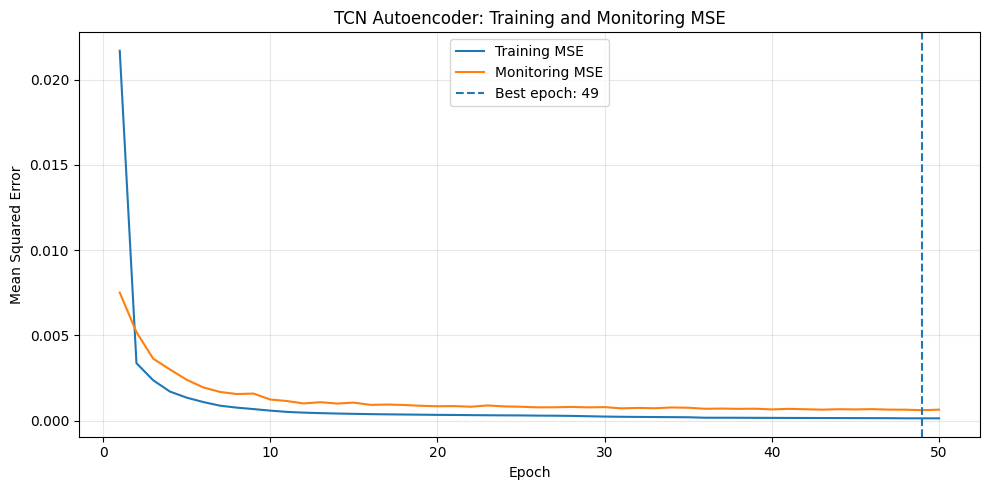

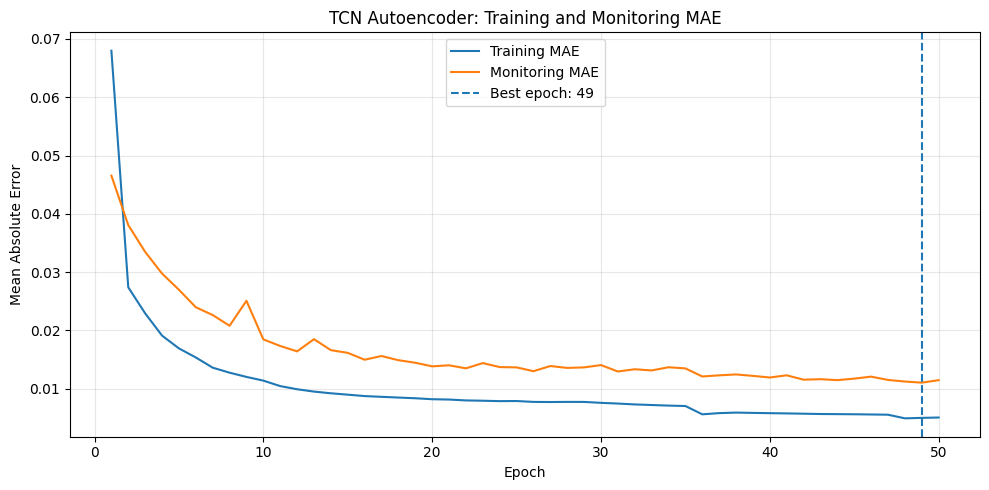


TCN AUTOENCODER TRAINING SUMMARY
Epochs completed: 50
Best epoch: 49
Best monitoring MSE: 0.00062031
Best monitoring RMSE: 0.02490610
Best monitoring MAE: 0.01103645
Total training time: 5.69 minutes

Saved artifacts:
Best model: /content/artifacts/tcn_preliminary/tcn_autoencoder_best.pth
Training history: /content/artifacts/tcn_preliminary/tcn_training_history.csv
Training metadata: /content/artifacts/tcn_preliminary/tcn_training_metadata.json
MSE plot: /content/artifacts/tcn_preliminary/tcn_training_mse.png
MAE plot: /content/artifacts/tcn_preliminary/tcn_training_mae.png

Best checkpoint restored successfully.
Model is in evaluation mode.
This was a preliminary single-configuration training run.


,epoch,learning_rate,train_mse,monitor_mse,train_rmse,monitor_rmse,train_mae,monitor_mae,epoch_seconds,best_checkpoint_updated
0,1,0.00100,0.021690,0.007513,0.147277,0.086678,0.067978,0.046543,8.814574,True
1,2,0.00100,0.003377,0.005199,0.058114,0.072102,0.027384,0.038065,6.771867,True
2,3,0.00100,0.002375,0.003640,0.048732,0.060330,0.022924,0.033469,6.690072,True
3,4,0.00100,0.001714,0.003010,0.041399,0.054862,0.019106,0.029751,6.684615,True
4,5,0.00100,0.001357,0.002406,0.036831,0.049049,0.016910,0.026971,6.871436,True
5,6,0.00100,0.001097,0.001955,0.033126,0.044212,0.015354,0.023971,6.709638,True
6,7,0.00100,0.000885,0.001692,0.029743,0.041133,0.013606,0.022634,6.979438,True
7,8,0.00100,0.000771,0.001567,0.027762,0.039581,0.012744,0.020797,6.479019,True
8,9,0.00100,0.000686,0.001596,0.026192,0.039947,0.012019,0.025077,7.337422,False
9,10,0.00100,0.000595,0.001248,0.024398,0.035325,0.011381,0.018456,6.900095,True


In [23]:
# 7.3 — Train the TCN Autoencoder

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

# --------------------------------------------------
# 1. Validate the existing training configuration
# --------------------------------------------------

assert len(X_train_seq) > 0, "Training sequences are empty."
assert len(X_monitor_seq) > 0, "Monitoring sequences are empty."

assert X_train_seq.ndim == 3, (
    "Training data must have shape (N, T, F)."
)

assert X_monitor_seq.ndim == 3, (
    "Monitoring data must have shape (N, T, F)."
)

assert X_train_seq.shape[1:] == X_monitor_seq.shape[1:], (
    "Training and monitoring sequence dimensions do not match."
)

assert len(train_dataset) == len(X_train_seq), (
    "Training dataset size does not match training sequences."
)

assert len(train_loader.dataset) == len(X_train_seq), (
    "Training DataLoader size does not match training sequences."
)

assert len(train_loader) > 0, "Training DataLoader is empty."

assert BATCH_SIZE > 0
assert MAX_EPOCHS > 0
assert EARLY_STOPPING_PATIENCE > 0

# Ensure the model and selected device use the same device type.
selected_device = torch.device(DEVICE)
tcn_model = tcn_model.to(selected_device)

model_device = next(tcn_model.parameters()).device

assert model_device.type == selected_device.type, (
    f"Model device {model_device} does not match "
    f"selected device {selected_device}."
)

# Ensure model and data dimensions are compatible.
assert X_train_seq.shape[2] == X_monitor_seq.shape[2]

# --------------------------------------------------
# 2. Prepare the monitoring DataLoader
# --------------------------------------------------

# This tensor shares memory with the NumPy array.
X_monitor_tensor = torch.from_numpy(X_monitor_seq)

monitor_dataset = TensorDataset(X_monitor_tensor)

monitor_loader = DataLoader(
    monitor_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(selected_device.type == "cuda")
)

# --------------------------------------------------
# 3. Configure the learning-rate scheduler
# --------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

# --------------------------------------------------
# 4. Configure output files
# --------------------------------------------------

# Verify this directory is appropriate for your environment.
OUTPUT_DIR = Path.cwd() / "artifacts" / "tcn_preliminary"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "tcn_autoencoder_best.pth"
HISTORY_PATH = OUTPUT_DIR / "tcn_training_history.csv"
METADATA_PATH = OUTPUT_DIR / "tcn_training_metadata.json"
MSE_PLOT_PATH = OUTPUT_DIR / "tcn_training_mse.png"
MAE_PLOT_PATH = OUTPUT_DIR / "tcn_training_mae.png"

print("Output directory:", OUTPUT_DIR.resolve())
print("Model device:", model_device)
print("Selected device:", selected_device)

# --------------------------------------------------
# 5. Initialize training records
# --------------------------------------------------

best_monitor_loss = float("inf")
best_monitor_mae = None
best_epoch = None

epochs_without_improvement = 0
training_history = []

training_start_time = time.time()

initial_learning_rate = float(
    optimizer.param_groups[0]["lr"]
)

print("\nTCN AUTOENCODER TRAINING")
print("=" * 72)
print(f"Training sequences: {len(train_dataset):,}")
print(f"Monitoring sequences: {len(monitor_dataset):,}")
print(f"Input shape per sequence: {tuple(X_train_seq.shape[1:])}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early-stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Initial learning rate: {initial_learning_rate:.6g}")
print("=" * 72)

# --------------------------------------------------
# 6. Training loop
# --------------------------------------------------

for epoch in range(1, MAX_EPOCHS + 1):

    epoch_start_time = time.time()
    learning_rate_used = float(optimizer.param_groups[0]["lr"])

    # ==============================================
    # Training phase
    # ==============================================

    tcn_model.train()

    train_squared_error = 0.0
    train_absolute_error = 0.0
    train_element_count = 0

    for (batch,) in train_loader:

        batch = batch.to(
            selected_device,
            non_blocking=(selected_device.type == "cuda")
        )

        optimizer.zero_grad(set_to_none=True)

        reconstruction = tcn_model(batch)

        loss = criterion(reconstruction, batch)

        loss.backward()
        optimizer.step()

        with torch.no_grad():

            squared_error = torch.sum(
                (reconstruction.detach() - batch) ** 2
            ).item()

            absolute_error = torch.sum(
                torch.abs(reconstruction.detach() - batch)
            ).item()

            train_squared_error += squared_error
            train_absolute_error += absolute_error
            train_element_count += batch.numel()

    if train_element_count == 0:
        raise RuntimeError("No training elements were processed.")

    train_mse = train_squared_error / train_element_count
    train_mae = train_absolute_error / train_element_count
    train_rmse = float(np.sqrt(train_mse))

    # ==============================================
    # Monitoring phase
    # ==============================================

    # No gradients or optimizer updates occur here.
    tcn_model.eval()

    monitor_squared_error = 0.0
    monitor_absolute_error = 0.0
    monitor_element_count = 0

    with torch.no_grad():

        for (batch,) in monitor_loader:

            batch = batch.to(
                selected_device,
                non_blocking=(selected_device.type == "cuda")
            )

            reconstruction = tcn_model(batch)

            squared_error = torch.sum(
                (reconstruction - batch) ** 2
            ).item()

            absolute_error = torch.sum(
                torch.abs(reconstruction - batch)
            ).item()

            monitor_squared_error += squared_error
            monitor_absolute_error += absolute_error
            monitor_element_count += batch.numel()

    if monitor_element_count == 0:
        raise RuntimeError("No monitoring elements were processed.")

    monitor_mse = monitor_squared_error / monitor_element_count
    monitor_mae = monitor_absolute_error / monitor_element_count
    monitor_rmse = float(np.sqrt(monitor_mse))

    # ==============================================
    # Checkpoint selection
    # ==============================================

    epoch_time = time.time() - epoch_start_time
    improved = monitor_mse < best_monitor_loss

    if improved:

        best_monitor_loss = monitor_mse
        best_monitor_mae = monitor_mae
        best_epoch = epoch

        epochs_without_improvement = 0

        torch.save(
            tcn_model.state_dict(),
            CHECKPOINT_PATH
        )

        checkpoint_status = "BEST CHECKPOINT SAVED"

    else:

        epochs_without_improvement += 1

        checkpoint_status = (
            f"No improvement "
            f"({epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE})"
        )

    # ==============================================
    # Record epoch results
    # ==============================================

    training_history.append({
        "epoch": epoch,
        "learning_rate": learning_rate_used,
        "train_mse": train_mse,
        "monitor_mse": monitor_mse,
        "train_rmse": train_rmse,
        "monitor_rmse": monitor_rmse,
        "train_mae": train_mae,
        "monitor_mae": monitor_mae,
        "epoch_seconds": epoch_time,
        "best_checkpoint_updated": improved
    })

    # Update the scheduler using monitoring MSE.
    scheduler.step(monitor_mse)

    next_learning_rate = float(
        optimizer.param_groups[0]["lr"]
    )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train MSE: {train_mse:.8f} | "
        f"Monitor MSE: {monitor_mse:.8f} | "
        f"Train MAE: {train_mae:.8f} | "
        f"Monitor MAE: {monitor_mae:.8f} | "
        f"LR: {learning_rate_used:.2e} | "
        f"Time: {epoch_time:.1f}s | "
        f"{checkpoint_status}"
    )

    if next_learning_rate < learning_rate_used:
        print(f"  Learning rate reduced to {next_learning_rate:.2e}")

    # ==============================================
    # Early stopping
    # ==============================================

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch}. "
            f"No monitoring-MSE improvement for "
            f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
        )

        break

# --------------------------------------------------
# 7. Verify and restore the best checkpoint
# --------------------------------------------------

if best_epoch is None or not CHECKPOINT_PATH.is_file():
    raise RuntimeError(
        "Training did not produce a valid best-model checkpoint."
    )

try:
    best_state = torch.load(
        CHECKPOINT_PATH,
        map_location=selected_device,
        weights_only=True
    )
except TypeError:
    best_state = torch.load(
        CHECKPOINT_PATH,
        map_location=selected_device
    )

tcn_model.load_state_dict(best_state)
tcn_model.eval()

total_training_time = time.time() - training_start_time

# --------------------------------------------------
# 8. Save training history
# --------------------------------------------------

history_df = pd.DataFrame(training_history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

# --------------------------------------------------
# 9. Save training metadata
# --------------------------------------------------

training_metadata = {
    "model": "TCN Autoencoder",
    "experiment_type": "preliminary_single_configuration",
    "seed": int(SEED),
    "device": str(model_device),
    "training_sequences": int(len(train_dataset)),
    "monitoring_sequences": int(len(monitor_dataset)),
    "sequence_length": int(X_train_seq.shape[1]),
    "feature_count": int(X_train_seq.shape[2]),
    "batch_size": int(BATCH_SIZE),
    "maximum_epochs": int(MAX_EPOCHS),
    "epochs_completed": int(len(training_history)),
    "best_epoch": int(best_epoch),
    "best_monitor_mse": float(best_monitor_loss),
    "best_monitor_rmse": float(np.sqrt(best_monitor_loss)),
    "best_monitor_mae": float(best_monitor_mae),
    "optimizer": type(optimizer).__name__,
    "optimizer_initial_learning_rate": initial_learning_rate,
    "optimizer_parameters": optimizer.defaults,
    "loss_function": type(criterion).__name__,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "min",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,
    "scheduler_min_learning_rate": 1e-6,
    "early_stopping_patience": int(EARLY_STOPPING_PATIENCE),
    "checkpoint_selection_metric": "monitor_mse",
    "total_training_seconds": float(total_training_time),
    "checkpoint": str(CHECKPOINT_PATH.resolve()),
    "training_history": str(HISTORY_PATH.resolve())
}

# Convert optimizer defaults to JSON-safe values.
training_metadata["optimizer_parameters"] = {
    key: value
    for key, value in optimizer.defaults.items()
    if isinstance(value, (str, int, float, bool, type(None)))
}

with METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(training_metadata, file, indent=4)

# --------------------------------------------------
# 10. Plot training and monitoring MSE
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    label="Training MSE"
)

plt.plot(
    history_df["epoch"],
    history_df["monitor_mse"],
    label="Monitoring MSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("TCN Autoencoder: Training and Monitoring MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(MSE_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 11. Plot training and monitoring MAE
# --------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_mae"],
    label="Training MAE"
)

plt.plot(
    history_df["epoch"],
    history_df["monitor_mae"],
    label="Monitoring MAE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.title("TCN Autoencoder: Training and Monitoring MAE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(MAE_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# 12. Display training summary
# --------------------------------------------------

print("\n" + "=" * 72)
print("TCN AUTOENCODER TRAINING SUMMARY")
print("=" * 72)

print(f"Epochs completed: {len(training_history)}")
print(f"Best epoch: {best_epoch}")
print(f"Best monitoring MSE: {best_monitor_loss:.8f}")
print(f"Best monitoring RMSE: {np.sqrt(best_monitor_loss):.8f}")
print(f"Best monitoring MAE: {best_monitor_mae:.8f}")
print(f"Total training time: {total_training_time / 60:.2f} minutes")

print("\nSaved artifacts:")
print(f"Best model: {CHECKPOINT_PATH.resolve()}")
print(f"Training history: {HISTORY_PATH.resolve()}")
print(f"Training metadata: {METADATA_PATH.resolve()}")
print(f"MSE plot: {MSE_PLOT_PATH.resolve()}")
print(f"MAE plot: {MAE_PLOT_PATH.resolve()}")

print("\nBest checkpoint restored successfully.")
print("Model is in evaluation mode.")
print("This was a preliminary single-configuration training run.")
print("=" * 72)

display(history_df)

In [26]:
from pathlib import Path
import shutil

# Existing TCN artifacts from the completed training run.
SOURCE_DIR = Path("/content/artifacts/tcn_preliminary")

# Your existing Google Drive artifacts folder.
DESTINATION_DIR = (
    Path("/content/drive/MyDrive/swat-artifacts")
    / "tcn_preliminary"
)

ARTIFACT_FILES = [
    "tcn_autoencoder_best.pth",
    "tcn_training_history.csv",
    "tcn_training_metadata.json",
    "tcn_training_mse.png",
    "tcn_training_mae.png",
]

# Confirm the source and destination exist.
if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Training artifacts not found: {SOURCE_DIR}"
    )

if not DESTINATION_DIR.parent.is_dir():
    raise FileNotFoundError(
        f"Google Drive destination folder not found: "
        f"{DESTINATION_DIR.parent}"
    )

# Check every source file before copying.
missing = [
    name for name in ARTIFACT_FILES
    if not (SOURCE_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing source files:\n" + "\n".join(missing)
    )

# Create the TCN subfolder if necessary.
DESTINATION_DIR.mkdir(parents=True, exist_ok=True)

# Copy and verify each artifact.
for name in ARTIFACT_FILES:
    source = SOURCE_DIR / name
    destination = DESTINATION_DIR / name

    shutil.copy2(source, destination)

    if (
        not destination.is_file()
        or destination.stat().st_size != source.stat().st_size
    ):
        raise IOError(f"Copy verification failed: {name}")

    print(f"VERIFIED: {name} ({destination.stat().st_size:,} bytes)")

print("\nAll five TCN artifacts were copied and verified.")
print(f"Google Drive location: {DESTINATION_DIR}")

VERIFIED: tcn_autoencoder_best.pth (172,853 bytes)
VERIFIED: tcn_training_history.csv (8,117 bytes)
VERIFIED: tcn_training_metadata.json (1,373 bytes)
VERIFIED: tcn_training_mse.png (61,322 bytes)
VERIFIED: tcn_training_mae.png (72,932 bytes)

All five TCN artifacts were copied and verified.
Google Drive location: /content/drive/MyDrive/swat-artifacts/tcn_preliminary


### 7.3.1 — Preliminary TCN Training Results

#### Training Configuration

The TCN Autoencoder was trained for a maximum of 50 epochs using 221,337 training sequences and monitored on 47,406 chronologically subsequent sequences. Each sequence contained 30 timesteps and 42 features.

Training used mean squared error (MSE), the Adam optimizer, an initial learning rate of 0.001, and a batch size of 256. A ReduceLROnPlateau scheduler reduced the learning rate when monitoring loss stopped improving. Early stopping used a patience of five epochs.

#### Observed Results

The lowest recorded monitoring MSE was 0.00062031 at epoch 49. The corresponding training MSE was 0.00014374, and the monitoring MAE was 0.01103645.

Monitoring MSE decreased from 0.00751307 in epoch 1 to 0.00062031 in epoch 49. The learning rate was reduced twice, reaching 0.00025 by epoch 48. Training completed all 50 epochs without triggering early stopping.

#### Interpretation

The decreasing monitoring loss indicates that reconstruction performance improved on the monitoring partition during training. The difference between training and monitoring losses warrants further observation but is not sufficient, by itself, to establish harmful overfitting.

The best checkpoint was recorded at epoch 49 based on monitoring MSE. This configuration remains preliminary: the model has not yet undergone systematic hyperparameter tuning or threshold calibration.

Reconstruction loss alone does not establish anomaly-detection effectiveness. The TCN's ability to distinguish anomalous from normal observations must be assessed separately using an appropriately calibrated threshold and a verified labelled evaluation dataset.

#### Limitations and Next Steps

- This is a single preliminary TCN configuration, not a tuned or final model.
- The monitoring partition was used for checkpoint selection and is therefore not an independent final evaluation set.
- No attack-detection performance is claimed from these reconstruction results.
- Hyperparameter tuning and threshold calibration remain assigned to Notebook 08.

The TCN training results are recorded. The next step is to implement and train the USAD model within this notebook, following the established experimental protocol.